In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)


In [18]:
df = pd.read_csv(r"C:\Users\hp\Downloads\bank (1).csv")

print(df.head())
print(df.shape)
print(df.columns.tolist())

   age         job  marital  education default  balance housing loan  contact  \
0   59      admin.  married  secondary      no     2343     yes   no  unknown   
1   56      admin.  married  secondary      no       45      no   no  unknown   
2   41  technician  married  secondary      no     1270     yes   no  unknown   
3   55    services  married  secondary      no     2476     yes   no  unknown   
4   54      admin.  married   tertiary      no      184      no   no  unknown   

   day month  duration  campaign  pdays  previous poutcome deposit  
0    5   may      1042         1     -1         0  unknown     yes  
1    5   may      1467         1     -1         0  unknown     yes  
2    5   may      1389         1     -1         0  unknown     yes  
3    5   may       579         1     -1         0  unknown     yes  
4    5   may       673         2     -1         0  unknown     yes  
(11162, 17)
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contac

In [19]:
print(df["deposit"].value_counts())

deposit
no     5873
yes    5289
Name: count, dtype: int64


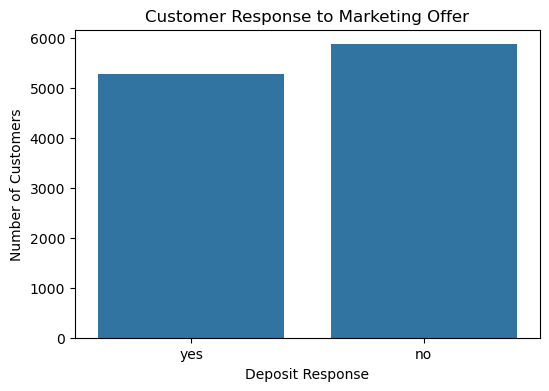

In [21]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x ="deposit")

plt.title("Customer Response to Marketing Offer")
plt.xlabel("Deposit Response")
plt.ylabel("Number of Customers")

plt.show()

In [22]:
#convert the target to 0 and 1
df["deposit"] = df["deposit"].map({
    "no":0,
    "yes":1
})

print(df["deposit"].value_counts())


deposit
0    5873
1    5289
Name: count, dtype: int64


In [23]:
#check for missing values
print(df.isnull().sum())

categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:
    print("\n",column)
    print(df[column].value_counts())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

 job
job
management       2566
blue-collar      1944
technician       1823
admin.           1334
services          923
retired           778
self-employed     405
student           360
unemployed        357
entrepreneur      328
housemaid         274
unknown            70
Name: count, dtype: int64

 marital
marital
married     6351
single      3518
divorced    1293
Name: count, dtype: int64

 education
education
secondary    5476
tertiary     3689
primary      1500
unknown       497
Name: count, dtype: int64

 default
default
no     10994
yes      168
Name: count, dtype: int64

 housing
housing
no     5881
yes    5281
Name: count, dtype: int64

 loan
loan
no     9702
yes    1460
Name: count, dtype: int64

 contact
contact

In [24]:
df_model = df.drop(columns=["duration"])

In [25]:
#separate predictors and target 
x = df_model.drop(columns=["deposit"])
y = df_model["deposit"]

print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: (11162, 15)
y shape: (11162,)


In [26]:
#identify numerical and categorical variables
numerical_features = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous"
]

categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome"
]

In [27]:
#split the data
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (8929, 15)
Testing data: (2233, 15)


In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [30]:
#create a logistic regression model
logistic_model = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced"
            )
        )
    ]
)
        

In [31]:
#train the model
logistic_model.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [34]:
#make predictions
y_pred = logistic_model.predict(x_test)

y_probability = logistic_model.predict_proba(x_test)[:,1]

print("Predicted Classes:")
print (y_pred)
print("\nPredicted Probabilities:")
print(y_probability)

Predicted Classes:
[0 1 1 ... 1 0 1]

Predicted Probabilities:
[0.38560507 0.5227543  0.77119444 ... 0.60215664 0.42713346 0.78155577]


In [35]:
#Evaluate the model
accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall= recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1=f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("LOGISTIC REGRESSION RESULTS")
print("-------------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:",round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:",round(recall, 4))
print("ROC-AUC:", round(roc_auc,4))

LOGISTIC REGRESSION RESULTS
-------------------------------
Accuracy: 0.6932
Precision: 0.7117
Recall: 0.5926
F1 Score: 0.5926
ROC-AUC: 0.7579


In [36]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.68      0.78      0.73      1175
           1       0.71      0.59      0.65      1058

    accuracy                           0.69      2233
   macro avg       0.70      0.69      0.69      2233
weighted avg       0.70      0.69      0.69      2233



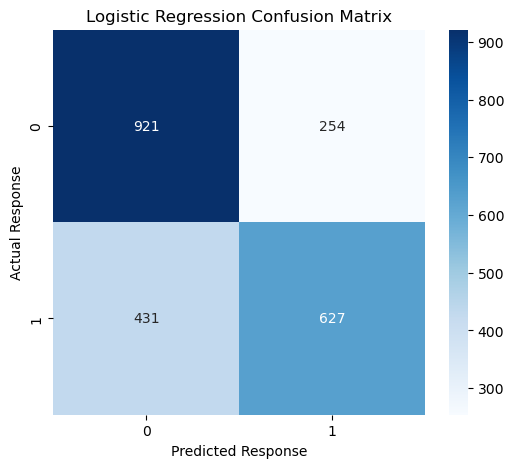

In [41]:
cm = confusion_matrix(y_test,y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Response")
plt.ylabel("Actual Response")

plt.show()

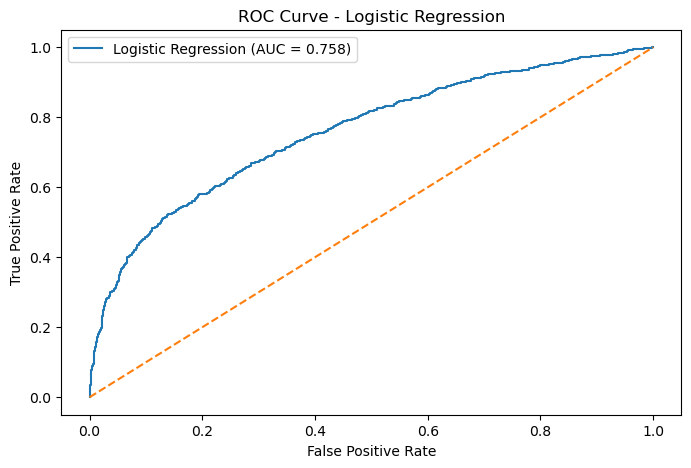

In [42]:
#ROC CURVE
fpr,tpr,thresholds = roc_curve(
    y_test,
    y_probability
)
plt.figure(figsize=(8,5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")

plt.legend()

plt.show()


In [43]:
random_forest_model=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=12,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(
    x_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [44]:
#predict using random forest 
rf_pred = random_forest_model.predict(x_test)
rf_probability=random_forest_model.predict_proba(
    x_test
)[:,1]

In [45]:
rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_auc = roc_auc_score(
    y_test,
    rf_probability
)

print("RANDOM FOREST RESULTS")
print("--------------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_auc, 4))

RANDOM FOREST RESULTS
--------------------------------
Accuracy : 0.7313
Precision: 0.7614
Recall   : 0.6304
F1 Score : 0.6898
ROC-AUC  : 0.7872


In [46]:
#compare the 2 models
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy
    ],
    "Precision": [
        precision,
        rf_precision
    ],
    "Recall": [
        recall,
        rf_recall
    ],
    "F1 Score": [
        f1,
        rf_f1
    ],
    "ROC-AUC": [
        roc_auc,
        rf_auc
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.693238   0.711691  0.592628  0.646725  0.757942
1        Random Forest  0.731303   0.761416  0.630435  0.689762  0.787229


In [48]:
#Identify the customers most likely to respond
customer_predictions = x_test.copy()

customer_predictions["Actual_Deposit"] = y_test.values

customer_predictions["Response_Probability"] = y_probability

customer_predictions["Predicted_Deposit"] = (
    customer_predictions["Response_Probability"] >= 0.50
).astype(int)

customer_predictions = customer_predictions.sort_values(
    by="Response_Probability",
    ascending=False
)

print(
    customer_predictions[
        [
            "age",
            "job",
            "marital",
            "education",
            "balance",
            "housing",
            "loan",
            "Response_Probability",
            "Predicted_Deposit"
        ]
    ].head(20)
)

      age            job   marital  education  balance housing loan  \
3380   84        retired   married  secondary    81204      no   no   
4294   26        student    single   tertiary      294      no   no   
3326   19        student    single    unknown      108      no   no   
3004   79        retired   married  secondary     8304      no   no   
3236   61  self-employed  divorced   tertiary    52587      no   no   
3365   57     management   married   tertiary    10583      no   no   
4856   76        retired  divorced    primary      802      no   no   
4970   68        retired   married  secondary     1146      no   no   
3917   41     unemployed    single   tertiary     7968      no   no   
3918   25        student    single  secondary      154      no   no   
3304   64        retired   married   tertiary     1644      no   no   
3357   60         admin.   married  secondary     3735      no   no   
3020   29     management    single   tertiary      572      no   no   
4034  

In [49]:
#create a high-priority marketing list
high_probability_customers = customer_predictions[
    customer_predictions["Response_Probability"] >= 0.70
]
print(
    "High-probability customers:",
    len(high_probability_customers)
)
print(
    high_probability_customers[
        [
            "age",
            "job",
            "marital",
            "education",
            "balance",
            "housing",
            "loan",
            "contact",
            "month",
            "Response_Probability"
        ]
    ]
)

High-probability customers: 458
      age            job   marital  education  balance housing loan  \
3380   84        retired   married  secondary    81204      no   no   
4294   26        student    single   tertiary      294      no   no   
3326   19        student    single    unknown      108      no   no   
3004   79        retired   married  secondary     8304      no   no   
3236   61  self-employed  divorced   tertiary    52587      no   no   
...   ...            ...       ...        ...      ...     ...  ...   
3589   65         admin.   married  secondary      952      no   no   
7143   60        retired  divorced   tertiary      380      no   no   
7190   55        retired   married   tertiary      357     yes   no   
1706   30     management    single   tertiary      364      no   no   
3381   86        retired   married    primary     5236      no   no   

        contact month  Response_Probability  
3380  telephone   apr              0.998842  
4294   cellular   mar  

In [50]:
#save the marketing list
high_probability_customers.to_csv(
    "customers_likely_to_respond.csv",
    index=False
)

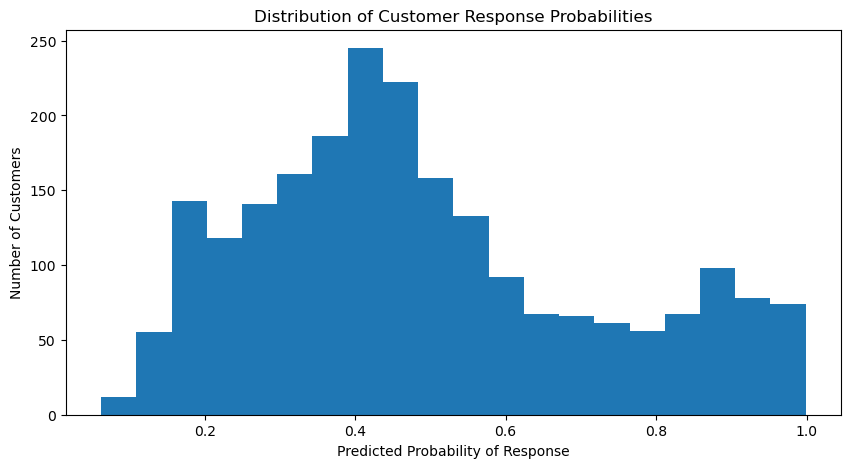

In [51]:
#visualize the predicted probabilities
plt.figure(figsize=(10, 5))

plt.hist(
    y_probability,
    bins=20
)

plt.xlabel("Predicted Probability of Response")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Response Probabilities")

plt.show()